# 03 · Does heavy rain lead to more cases, and when?

**Goal:** test the core idea of the product: heavy rain → flooding → wading → leptospirosis
cases some weeks later. We want to know:

1. **Timing:** how many weeks after rain do cases rise?
2. **Size:** how much do they rise, and does more rain mean more cases?
3. **Robustness:** does it hold without the 2011–12 outbreaks, and without Iloilo?
4. **Forecast value:** does knowing the rain improve predictions on unseen years?

Season matters throughout: rain and cases both peak in the wet season (notebook 02), so we
always compare against **what's normal for that week of the year**.

In [1]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

from common import *

style()
LAGS = range(0, 9)
d = panel()
d = add_lags(d, "rain", LAGS)
d["expected"] = seasonal_expected(d)

## 1. Rain at a glance

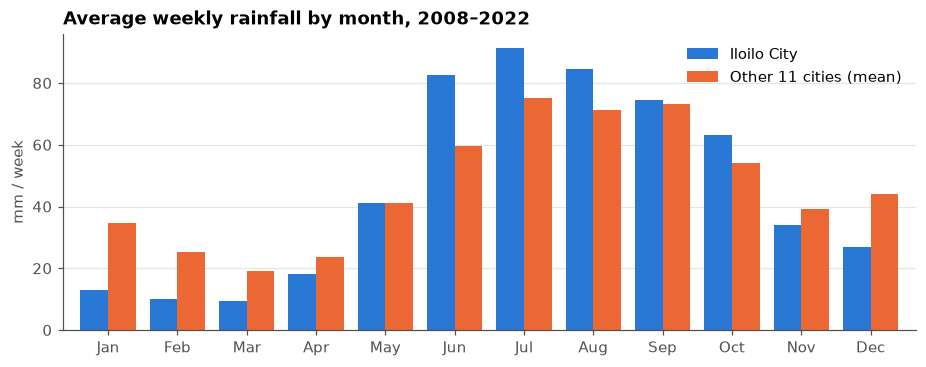

In [2]:
grp = np.where(d.city == ILOILO, ILOILO, "Other 11 cities (mean)")
monthly = d.groupby([grp, d.date.dt.month]).rain.mean().unstack(0)
ax = monthly.plot.bar(color=[BLUE, ORANGE], width=0.8, figsize=(10, 3.5))
ax.set_xticklabels(pd.date_range("2000-01", periods=12, freq="MS").strftime("%b"), rotation=0)
ax.set(title="Average weekly rainfall by month, 2008–2022", xlabel="", ylabel="mm / week")
ax.grid(axis="x", visible=False)
plt.show()

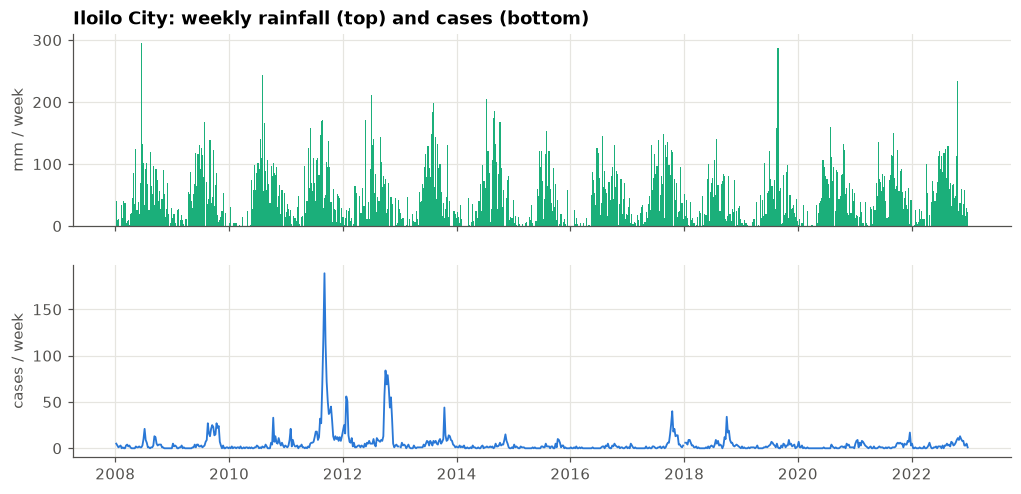

In [3]:
il = d[d.city == ILOILO]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
a1.bar(il.date, il.rain, width=7, color=AQUA)
a1.set(title="Iloilo City: weekly rainfall (top) and cases (bottom)", ylabel="mm / week")
a2.plot(il.date, il.cases, color=BLUE, linewidth=1.2)
a2.set(ylabel="cases / week")
plt.show()

**Takeaway:** Iloilo's rain follows the same wet season (June–November). The big case spikes
(2011, 2012, 2017, 2018) come after the heaviest rain weeks. The rest of the notebook tests
whether that holds up.

## 2. Timing: correlation at each lag

For each city we remove the seasonal average from both rain and cases (leaving the
*anomaly*: wetter or sicker than usual for that week), then correlate cases with rain from
*k* weeks earlier.

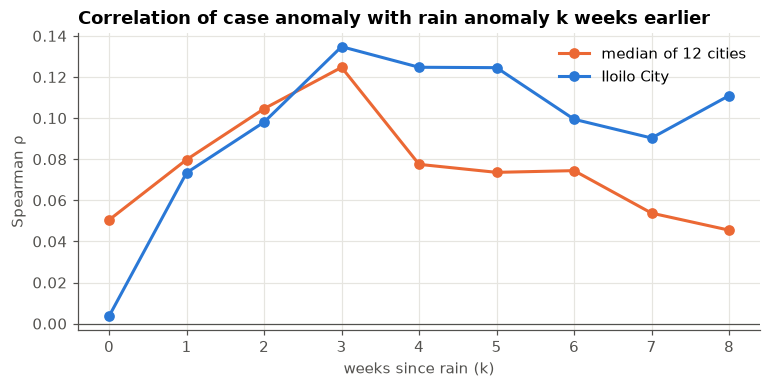

lag,0,1,2,3,4,5,6,7,8
median of 12 cities,0.050,0.080,0.105,0.125,0.077,0.074,0.074,0.054,0.045
Iloilo City,0.004,0.073,0.098,0.135,0.125,0.125,0.099,0.090,0.111


In [4]:
anom = lambda col: d[col] - d.groupby(["city", "woy"])[col].transform("mean")
d["case_anom"] = anom("cases")
rows = []
for k in LAGS:
    a = d.assign(rain_anom=anom(f"rain_l{k}"))
    r = a.groupby("city")[["case_anom", "rain_anom"]].apply(lambda x: x.corr("spearman").iloc[0, 1])
    rows.append({"lag": k, "median of 12 cities": r.median(), ILOILO: r[ILOILO]})
lagcorr = pd.DataFrame(rows).set_index("lag")

ax = lagcorr.plot(color=[ORANGE, BLUE], marker="o", figsize=(8, 3.5))
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set(title="Correlation of case anomaly with rain anomaly k weeks earlier",
       xlabel="weeks since rain (k)", ylabel="Spearman ρ")
plt.show()
lagcorr.round(3).T

**Takeaway:** the correlation is near zero for same-week rain and **peaks 3 weeks after rain**.
This matches leptospirosis's 1–2 week incubation plus time to see a doctor and get
reported. In Iloilo it stays elevated longer (out to ~8 weeks). The correlations are small
because most weeks are quiet. The next sections look at the big-rain weeks directly.

## 3. Size: what happens after the heaviest rain weeks?

An **event study**: take each city's wettest 2% of weeks, then compare observed cases in the
following weeks with what's normal for that time of year. A ratio of 2 means twice the usual.

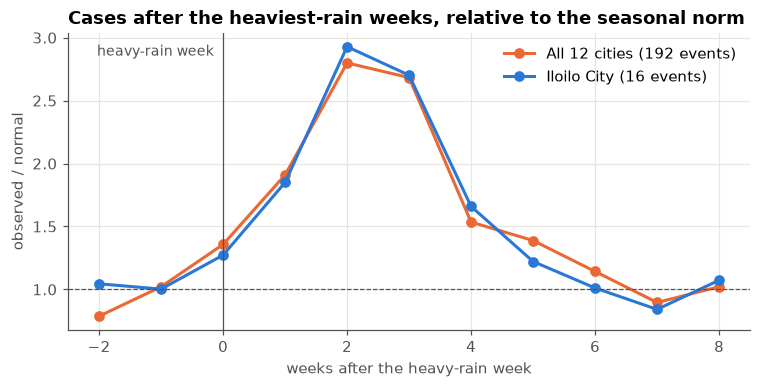

,-2,-1,0,1,2,3,4,5,6,7,8
all cities,0.79,1.02,1.36,1.91,2.80,2.68,1.54,1.39,1.14,0.90,1.02
Iloilo City,1.04,1.00,1.27,1.85,2.93,2.70,1.66,1.22,1.01,0.84,1.07


In [5]:
def event_ratio(x: pd.DataFrame, horizons=range(-2, 9)) -> pd.Series:
    x = x.copy()
    ev = x.groupby("city").rain.transform(lambda s: s >= s.quantile(0.98))
    g = x.groupby("city")
    out = {h: g.cases.shift(-h)[ev].sum() / g.expected.shift(-h)[ev].sum() for h in horizons}
    return pd.Series(out, name=f"{int(ev.sum())} events")

ev_all, ev_il = event_ratio(d), event_ratio(d[d.city == ILOILO])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ev_all.index, ev_all, color=ORANGE, marker="o", label=f"All 12 cities ({ev_all.name})")
ax.plot(ev_il.index, ev_il, color=BLUE, marker="o", label=f"{ILOILO} ({ev_il.name})")
ax.axhline(1, color=MUTED, linewidth=0.8, linestyle="--")
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.text(-0.15, ax.get_ylim()[1] * 0.97, "heavy-rain week", color=MUTED, fontsize=9, ha="right", va="top")
ax.set(title="Cases after the heaviest-rain weeks, relative to the seasonal norm",
       xlabel="weeks after the heavy-rain week", ylabel="observed / normal")
ax.legend(loc="upper right")
plt.show()
pd.DataFrame({"all cities": ev_all, ILOILO: ev_il}).round(2).T

**Takeaway:** before the storm, cases are at normal levels (ratio ≈ 1). They rise to **nearly
3× normal two weeks after** the heaviest rain, and are back to normal by about week 6. The
**0–6 week window** after heavy rain is when action pays off.

## 4. A model that controls for everything at once

The event study is simple but doesn't control for year-to-year swings (e.g. outbreak years). A
**negative binomial regression** (suited to overdispersed counts, notebook 02) estimates the
effect of rain at each lag while holding city, year and season fixed:

`cases ~ city + year + season + log(1 + rain) at lags 0–8`

The result for each lag is a **rate ratio**: how much cases multiply when that week's rain is
about 2.7× (one log unit) higher.

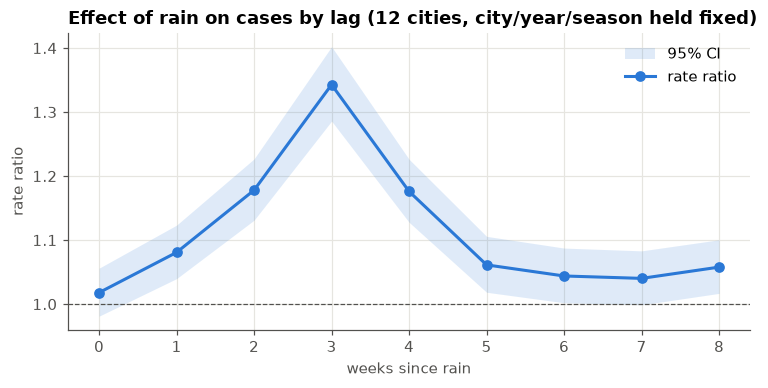

lag,0,1,2,3,4,5,6,7,8
rate_ratio,1.02,1.08,1.18,1.34,1.18,1.06,1.04,1.04,1.06
lo,0.98,1.04,1.13,1.29,1.13,1.02,1.00,1.00,1.02
hi,1.06,1.12,1.23,1.40,1.23,1.11,1.09,1.08,1.10


In [6]:
for k in LAGS:
    d[f"lr{k}"] = np.log1p(d[f"rain_l{k}"])
SEASON = "np.sin(2 * np.pi * woy / 52) + np.cos(2 * np.pi * woy / 52)"
LAG_TERMS = " + ".join(f"lr{k}" for k in LAGS)
NB = sm.families.NegativeBinomial(alpha=1.0)
fit_data = d.dropna(subset=["cases"] + [f"lr{k}" for k in LAGS])

def lag_curve(x: pd.DataFrame) -> pd.DataFrame:
    m = smf.glm(f"cases ~ C(city) + C(year) + {SEASON} + {LAG_TERMS}", x, family=NB).fit()
    ci = m.conf_int().loc[[f"lr{k}" for k in LAGS]]
    out = pd.DataFrame({"rate_ratio": np.exp(m.params[ci.index]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])})
    out.index = pd.Index(LAGS, name="lag")
    return out

curve = lag_curve(fit_data)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.fill_between(curve.index, curve.lo, curve.hi, color=BLUE, alpha=0.15, linewidth=0, label="95% CI")
ax.plot(curve.index, curve.rate_ratio, color=BLUE, marker="o", label="rate ratio")
ax.axhline(1, color=MUTED, linewidth=0.8, linestyle="--")
ax.set(title="Effect of rain on cases by lag (12 cities, city/year/season held fixed)",
       xlabel="weeks since rain", ylabel="rate ratio")
ax.legend()
plt.show()
curve.round(2).T

**Takeaway:** with city, year and season held fixed, the effect still **peaks 2–3 weeks after
rain** and is clearly above 1 there. Same-week rain has no effect. This is the lag structure
the forecast model uses.

## 5. Dose-response: does more rain mean more cases?

Group weekly rain from **two weeks earlier** into bands and compare each band with dry weeks
(under 10 mm), using the same controls.

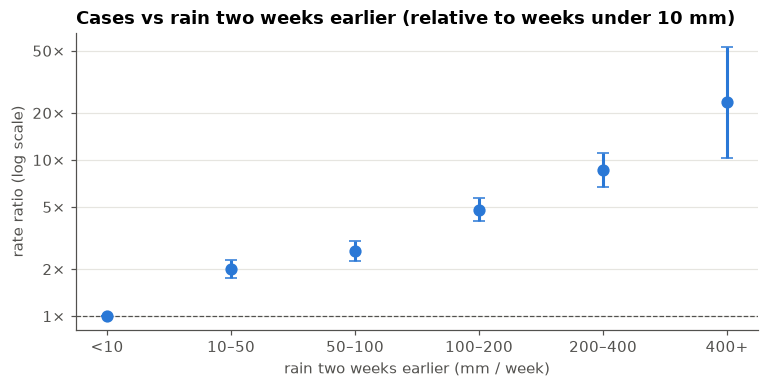

,<10,10–50,50–100,100–200,200–400,400+
rate_ratio,1.0,2.00,2.60,4.80,8.58,23.37
lo,1.0,1.75,2.25,4.06,6.67,10.28
hi,1.0,2.29,3.02,5.69,11.03,53.15
weeks,2539.0,3356.00,2271.00,903.00,187.00,8.00


In [7]:
bands = [-1, 10, 50, 100, 200, 400, np.inf]
labels = ["<10", "10–50", "50–100", "100–200", "200–400", "400+"]
fit_data["rain_band"] = pd.cut(fit_data.rain_l2, bands, labels=labels)
m = smf.glm(f"cases ~ C(city) + C(year) + {SEASON} + C(rain_band)", fit_data, family=NB).fit()
ci = m.conf_int().filter(like="rain_band", axis=0)
dose = pd.DataFrame({"rate_ratio": np.exp(m.params[ci.index]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])})
dose.index = labels[1:]
dose.loc["<10"] = [1, 1, 1]
dose = dose.loc[labels]
dose["weeks"] = fit_data.rain_band.value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(dose.index, dose.rate_ratio, yerr=[dose.rate_ratio - dose.lo, dose.hi - dose.rate_ratio],
            fmt="o", color=BLUE, capsize=4, markersize=7)
ax.axhline(1, color=MUTED, linewidth=0.8, linestyle="--")
ax.set_yscale("log")
ax.set_yticks([1, 2, 5, 10, 20, 50])
ax.yaxis.set_minor_locator(plt.matplotlib.ticker.NullLocator())
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set(title="Cases vs rain two weeks earlier (relative to weeks under 10 mm)",
       xlabel="rain two weeks earlier (mm / week)", ylabel="rate ratio (log scale)")
ax.grid(axis="x", visible=False)
plt.show()
dose.round(2).T

**Takeaway:** the effect grows steadily with rain: **2× at 10–50 mm, ~5× at 100–200 mm,
~9× at 200–400 mm** compared with a dry week. The 400+ band has only 8 weeks, so its interval
is very wide. A steady dose-response is what we'd expect if the link is real rather than a
coincidence.

## 6. Robustness

Is the lag curve just the 2011–12 outbreaks, or just Iloilo? Re-fit without them.

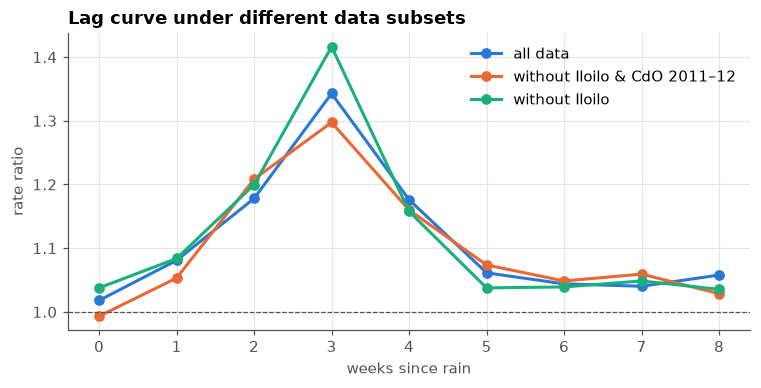

lag,0,1,2,3,4,5,6,7,8
all data,1.02,1.08,1.18,1.34,1.18,1.06,1.04,1.04,1.06
without Iloilo & CdO 2011–12,0.99,1.05,1.21,1.30,1.16,1.07,1.05,1.06,1.03
without Iloilo,1.04,1.08,1.20,1.42,1.16,1.04,1.04,1.05,1.04


In [8]:
outbreak = fit_data.city.isin([ILOILO, "Cagayan de Oro City"]) & fit_data.year.isin([2011, 2012])
variants = {
    "all data": fit_data,
    "without Iloilo & CdO 2011–12": fit_data[~outbreak],
    "without Iloilo": fit_data[fit_data.city != ILOILO],
}
robust = pd.DataFrame({name: lag_curve(x).rate_ratio for name, x in variants.items()})
ax = robust.plot(color=[BLUE, ORANGE, AQUA], marker="o", figsize=(8, 3.5))
ax.axhline(1, color=MUTED, linewidth=0.8, linestyle="--")
ax.set(title="Lag curve under different data subsets", xlabel="weeks since rain", ylabel="rate ratio")
plt.show()
robust.round(2).T

**Takeaway:** the curve keeps its shape and its 2–3 week peak in every subset. The rain effect
isn't an artefact of one storm or one city.

## 7. Forecast value: does rain help predict unseen years?

Fit on **2008–2017**, predict **2018–2022**, forecasting cases **h weeks ahead** using only what's
known today. Compare three models:

- **Seasonal only:** city + season
- **+ recent cases:** also this week's and recent weeks' case counts
- **+ rain:** also this and the past 6 weeks' rain

Error is the Poisson deviance (lower is better). The question is how much adding rain lowers it.

In [9]:
def backtest(h: int) -> pd.DataFrame:
    x = d.dropna(subset=["cases"]).copy()  # skip the 2 missing PIDSR weeks
    g = x.groupby("city")
    x["y"] = g.cases.shift(-h)
    x["c0"], x["c1"] = np.log1p(x.cases), np.log1p(g.cases.shift(1))
    x["c4"] = np.log1p(g.cases.transform(lambda s: s.rolling(4).mean()))
    x["woy"] = (x.woy + h - 1) % 52 + 1  # season of the target week
    rain = " + ".join(f"lr{k}" for k in range(7))
    x = x.dropna(subset=["y", "c1", "c4"] + [f"lr{k}" for k in range(7)])
    train, test = x[x.year <= 2017], x[x.year >= 2018]
    specs = {"seasonal only": f"C(city) + {SEASON}",
             "+ recent cases": f"C(city) + {SEASON} + c0 + c1 + c4",
             "+ rain": f"C(city) + {SEASON} + c0 + c1 + c4 + {rain}"}
    out = {}
    for name, rhs in specs.items():
        pred = smf.glm(f"y ~ {rhs}", train, family=NB).fit().predict(test)
        dev = pd.Series(sm.families.Poisson().resid_dev(test.y, pred) ** 2, index=test.index)
        out[name] = {"all cities": dev.mean(), ILOILO: dev[test.city == ILOILO].mean()}
    return pd.DataFrame(out).T.assign(h=h)

bt = {h: backtest(h) for h in (1, 2, 3)}
gain = pd.DataFrame({h: 1 - t.loc["+ rain"] / t.loc["+ recent cases"] for h, t in bt.items()}).T.drop(columns="h")
gain.index.name = "h"
pd.concat(bt.values()).round(3)

,all cities,Iloilo City,h
seasonal only,1.949,4.639,1
+ recent cases,1.260,2.343,1
+ rain,1.142,2.136,1
seasonal only,1.943,4.666,2
+ recent cases,1.554,2.750,2
+ rain,1.380,2.655,2
seasonal only,1.947,4.693,3
+ recent cases,1.719,3.235,3
+ rain,1.549,3.558,3


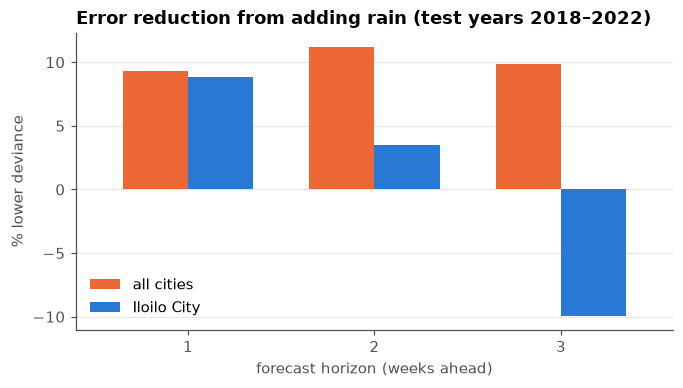

,all cities,Iloilo City
h,,
1,9.3,8.8
2,11.2,3.5
3,9.9,-10.0


In [10]:
ax = (gain * 100).plot.bar(color=[ORANGE, BLUE], width=0.7, figsize=(7, 3.5))
ax.set(title="Error reduction from adding rain (test years 2018–2022)",
       xlabel="forecast horizon (weeks ahead)", ylabel="% lower deviance")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="x", visible=False)
plt.show()
(gain * 100).round(1)

**Takeaways**
- **Across all cities**, adding rain lowers error by **~9–11%** at every horizon.
- **For Iloilo the gain shrinks with horizon and turns negative**: about 9% at 1 week, 4% at
  2 weeks, and **10% worse at 3 weeks**. Over all weeks, quiet weeks dominate, and the pooled
  rain effect doesn't transfer cleanly to Iloilo's 2018–2022 test years at longer range.
- ⚠️ The 3-week result is a red flag for 3-week Iloilo forecasts. Before relying on the
  model at h = 3, check it on post-storm weeks (where the event study says the signal is)
  and consider an Iloilo-specific term.

## Summary

| Question | Answer |
|---|---|
| Timing | Cases peak **2–3 weeks** after heavy rain (rate ratio 1.34 at lag 3), back to normal by ~week 6 |
| Size | **~2.8× the seasonal norm** two weeks after the heaviest rain weeks (Iloilo: 2.9×) |
| Dose-response | More rain → more cases, steadily |
| Robustness | Holds without the 2011–12 outbreaks and without Iloilo |
| Forecast value | ~10% lower error across cities; for Iloilo +9% at 1 week, +4% at 2, **−10% at 3** |

**For the model:** a negative binomial GLM pooled across 12 cities, with city, season and
rain at lags 0–8 weeks. The rain signal is clear and robust, but its forecast value for Iloilo
is limited beyond 2 weeks. Judge the model on post-storm weeks, and treat 3-week Iloilo
forecasts with caution until that's resolved.